# CNN Model

In [1]:
import os, shutil, pathlib
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay, classification_report
import keras
from keras import layers
from keras.utils import image_dataset_from_directory
import tensorflow as tf
import numpy as np

from PIL import Image
import time

keras.utils.set_random_seed(2)

base_dir = pathlib.Path("./datasets/dinnerware_mix_background")

C:\Users\miner\anaconda3\envs\keras\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
'''
remove later?

categories = ["bowl", "glass", "mug", "plate"]
splits = ["train", "validation", "test"]
image_extensions = ('.jpg', '.jpeg')

def count_dataset_images():
    for split in splits:
        print(f"\nsplit: {split}")
        total = 0

        for category in categories:
            folder = base_dir / split / category

            image_count = sum(
                1 for filename in os.listdir(folder)
                if filename.lower().endswith(image_extensions)
            )

            total += image_count

            print(f"  {category}: {image_count} images")

        print(f"  Total: {total} images")


count_dataset_images()

'''


split: train
  bowl: 68 images
  glass: 74 images
  mug: 78 images
  plate: 76 images
  Total: 296 images

split: validation
  bowl: 25 images
  glass: 22 images
  mug: 21 images
  plate: 25 images
  Total: 93 images

split: test
  bowl: 26 images
  glass: 24 images
  mug: 21 images
  plate: 24 images
  Total: 95 images


## Data Preprossing

In [3]:
train_dataset = image_dataset_from_directory(
    base_dir / "train",
    image_size = (224, 224),
    batch_size = 32,
    seed=123,
)
validation_dataset = image_dataset_from_directory(
    base_dir / "validation",
    image_size = (224, 224),
    batch_size = 32,
    shuffle=False,
    seed=123,
)
test_dataset = image_dataset_from_directory(
    base_dir / "test",
    image_size = (224, 224),
    batch_size = 32,
    shuffle=False,
    seed=123,
)

for data_batch, labels_batch in train_dataset:
    print("data batch shape:", data_batch.shape)
    print("labels batch shape:", labels_batch.shape)
    break

Found 296 files belonging to 4 classes.
Found 93 files belonging to 4 classes.
Found 95 files belonging to 4 classes.
data batch shape: (32, 224, 224, 3)
labels batch shape: (32,)


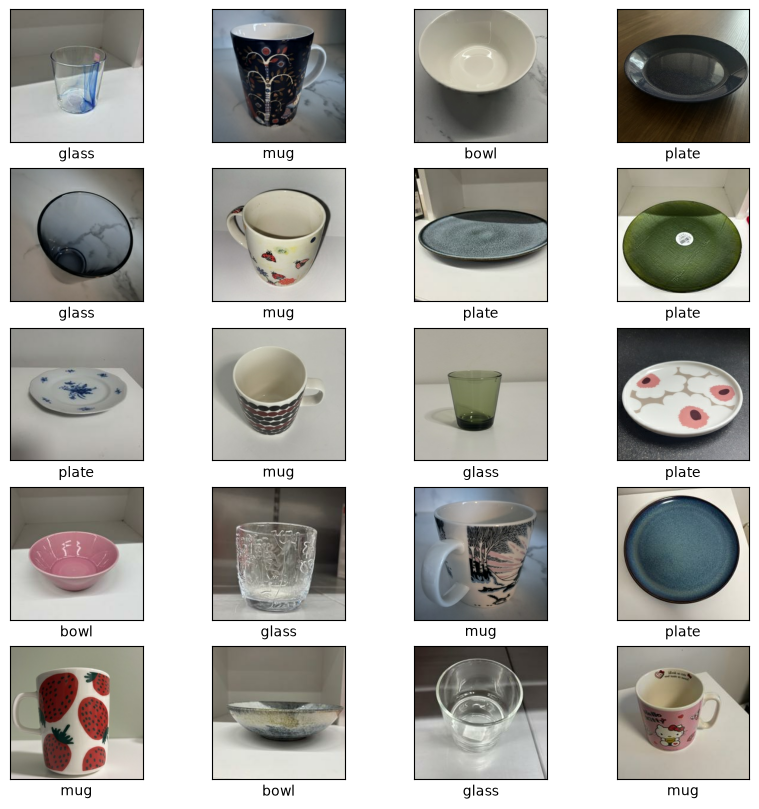

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

class_names = train_dataset.class_names

for images, labels in train_dataset.take(1):
    for i in range(20):
        plt.subplot(5, 4, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)

        plt.imshow(images[i].numpy().astype("uint8"))
        plt.xlabel(class_names[labels[i]])

plt.show()

## Modelling

In [7]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.2),
        layers.RandomZoom(0.2),
        layers.RandomContrast(0.2)
    ]
)

model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1.0/255),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(256, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dropout(0.10),
    layers.Dense(len(class_names), activation="softmax"),
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 220, 220, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 110, 110, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 108, 108, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │       147,460 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,124 (2.08 MB)

 Trainable params: 545,124 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

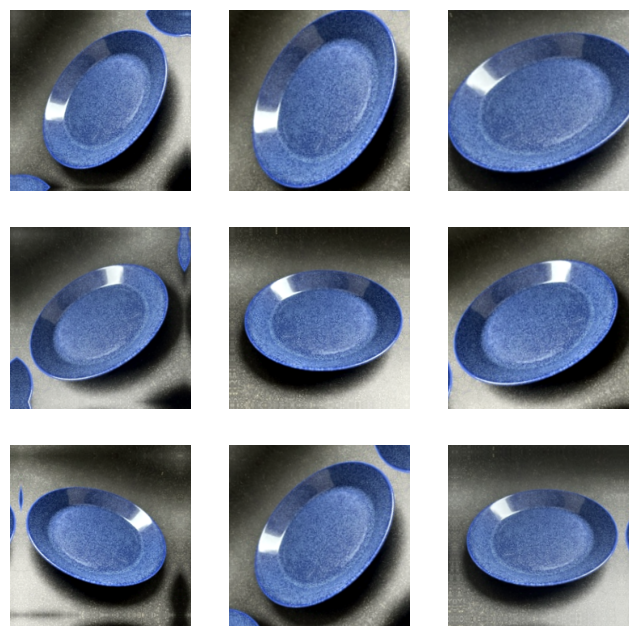

In [6]:
for images, labels in train_dataset.take(1):
    img = images[0:1]

plt.figure(figsize=(8, 8))
for i in range(9):
    aug = data_augmentation(img, training=True)
    plt.subplot(3, 3, i + 1)
    plt.imshow(keras.ops.convert_to_numpy(aug[0]).astype("uint8"))
    plt.axis("off")
plt.show()

## Compile and train the model

In [8]:
model.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(),
    optimizer=keras.optimizers.Adam(),
    metrics=["accuracy"],
)

In [9]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="convnet_from_scratch_with_augmentation.keras",
        save_best_only=True,
        monitor="val_loss"),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", 
        patience=7, 
        restore_best_weights=True)
]


t0 = time.time()

history = model.fit(
    train_dataset, 
    epochs=70, 
    validation_data=validation_dataset, 
    callbacks=callbacks)

train_time = time.time() - t0
print(f"Training time: {train_time:.1f} s")

Epoch 1/70


C:\Users\miner\anaconda3\envs\keras\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


10/10 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - accuracy: 0.2534 - loss: 1.4208 - val_accuracy: 0.2473 - val_loss: 1.3775
Epoch 2/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.3277 - loss: 1.3736 - val_accuracy: 0.3656 - val_loss: 1.3069
Epoch 3/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 25s 3s/step - accuracy: 0.3885 - loss: 1.2966 - val_accuracy: 0.3978 - val_loss: 1.2855
Epoch 4/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.3784 - loss: 1.3197 - val_accuracy: 0.5161 - val_loss: 1.1952
Epoch 5/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.4189 - loss: 1.2482 - val_accuracy: 0.4731 - val_loss: 1.1496
Epoch 6/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 29s 3s/step - accuracy: 0.4493 - loss: 1.2050 - val_accuracy: 0.4731 - val_loss: 1.1052
Epoch 7/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 28s 3s/step - accuracy: 0.4291 - loss: 1.1748 - val_accuracy: 0.4624 - val_loss: 1.1667
Epoch 8/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 27s 3s/step - accuracy: 0.4595 - loss: 1.2067 - val_accuracy: 0.4516 - val_loss: 1.2163
Epo

## Learning Curves

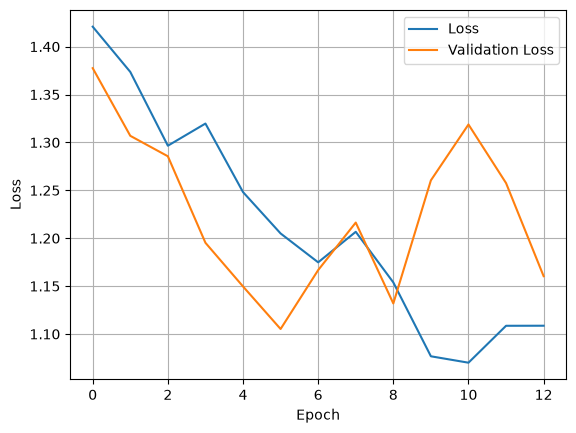

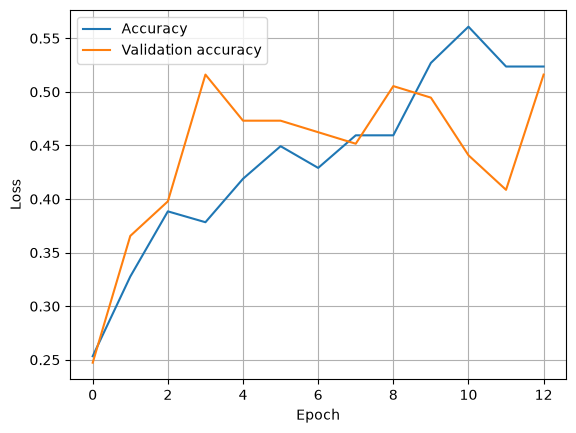

In [10]:
plt.plot(history.history["loss"], label="Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

plt.plot(history.history["accuracy"], label="Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

## Test perfomance

In [11]:
test_model = keras.models.load_model("convnet_from_scratch_with_augmentation.keras")
test_loss, test_acc = test_model.evaluate(test_dataset)

print(f"Test accuracy: {test_acc:.3f}")
print(f"Test loss: {test_loss:.3f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 455ms/step - accuracy: 0.4737 - loss: 1.2338
Test accuracy: 0.474
Test loss: 1.234


In [12]:
y_true = np.concatenate([y for x, y in test_dataset], axis=0)

probs = test_model.predict(test_dataset)
y_pred = np.argmax(probs, axis=1)

print(classification_report(y_true, y_pred, target_names=class_names))

3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 707ms/step
              precision    recall  f1-score   support

        bowl       0.50      0.19      0.28        26
       glass       0.45      0.71      0.55        24
         mug       0.39      0.43      0.41        21
       plate       0.58      0.58      0.58        24

    accuracy                           0.47        95
   macro avg       0.48      0.48      0.45        95
weighted avg       0.48      0.47      0.45        95



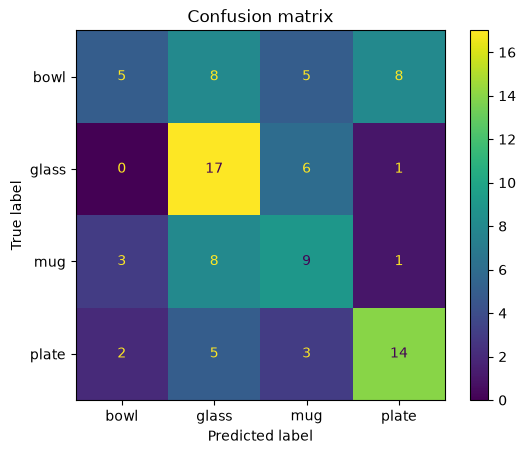

In [13]:
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot()
plt.title("Confusion matrix")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


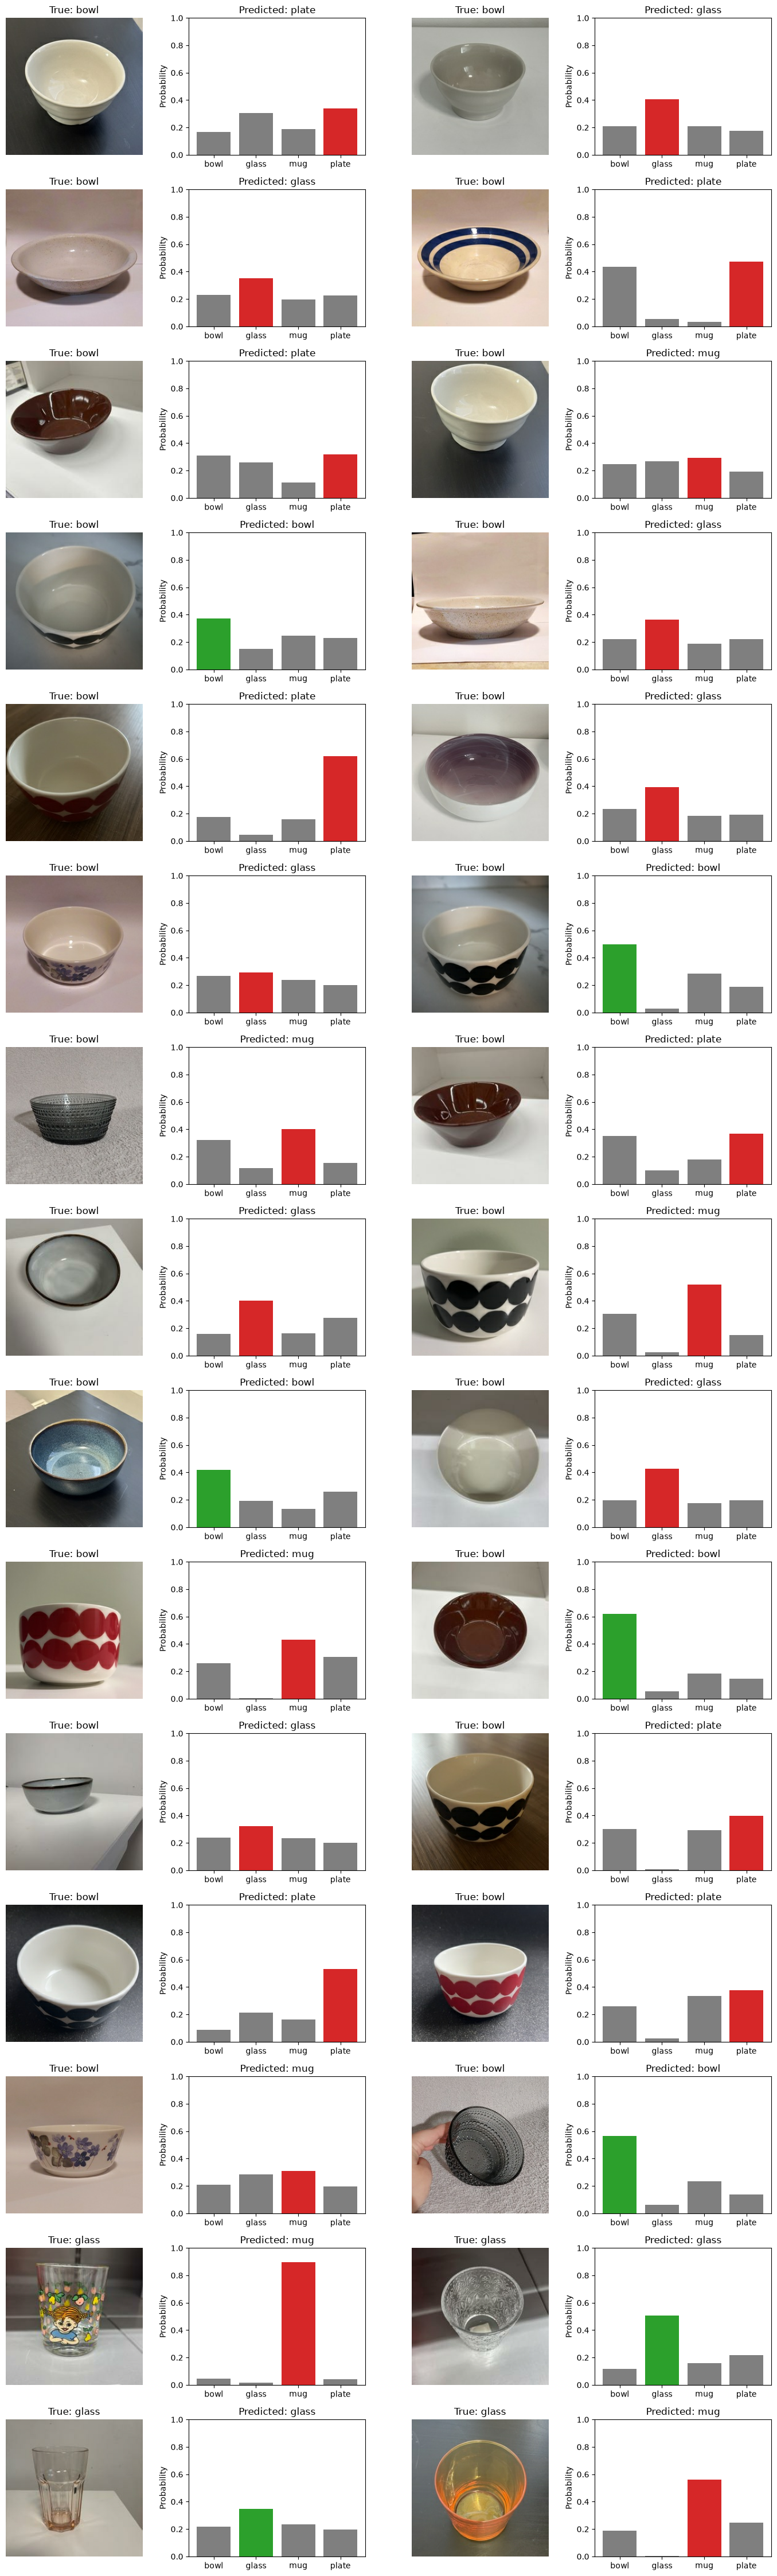

In [14]:
x, y = next(iter(test_dataset)) 
probs = test_model.predict(x)

start = 0
images_n = 30
rows = images_n // 2

plt.figure(figsize=(14, 3 * rows))

for k in range(images_n):
    i = start + k
    true_label = int(y[i])
    pred_label = int(np.argmax(probs[i]))
    correct = true_label == pred_label

    plt.subplot(rows, 4, 2 * k + 1)
    plt.imshow(x[i].numpy().astype("uint8"))
    plt.axis("off")
    plt.title(f"True: {class_names[true_label]}")

    plt.subplot(rows, 4, 2 * k + 2)
    colors = ["tab:gray"] * len(class_names)
    colors[pred_label] = "tab:green" if correct else "tab:red"
    plt.bar(class_names, probs[i], color=colors)
    plt.ylim(0, 1)
    plt.ylabel("Probability")
    plt.title(f"Predicted: {class_names[pred_label]}")

plt.tight_layout()
plt.show()

In [15]:
## Kirjoitetaan uuden notebookiin

## Dataset description Riikka

## Mallien suorituskyvyn vertailun: Nur

## Kohtaamasi haasteet ja ratkaisut Anni
- Kuvien ottaaminen, taustan päättääminen, esim: värikas tai musta-valkoinen, asento
- Kuvien esikäsittely: rajaus, koon muuttaminen.
- Kuvien laittaminen repoon
- Datan jakaminen: eri hakemistoihin harjoitus-, validointi- ja testidatalle,
- Datan jaon vaikeus: manuaalinen ja automaattinen skriptilla.
- Ylioppimiseen vähentäminen, hyvää tarkkuus, ja loss
- Finetuned mallin ajaamiseen hiitaus: piti miettiä huolellaa mitä muokkaa, ennen kuin ajaa malli.

## Pohdinnan eri mallien soveltuvuudesta ongelmaan Sandra
- CNN malli ei soveltuu koviin hyvin, kun meillä on vähän dataa.
- Feature_Extraction_VGG16 malli antaa parrempia tuloksia, on paljon nopeampi verrattuna CNN malli, mutta tulos ei ollut 100% prosenttin tarkkudella, loss... 
- Fine_tuned malli on erittäin hidas verrattuna muu 2 malli...

## Teköälyn käyttö Anni
- kuvien esitkäsittely skripti
- kuvien alustava jakoon ennen kuin manuaalisesti jaoteltu
- Debuggaus
- Plottaukseen